<a href="https://colab.research.google.com/github/Alphaddeta26/Mental_health_risk_prediction_system/blob/main/capstone_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip -q install gradio scikit-learn pandas numpy matplotlib seaborn joblib


In [4]:
import re, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

LABELS = {0: "Low risk", 1: "Moderate risk", 2: "High risk"}


(900, 2)


,text,label
860,honestly had a nice chat with an old friend th...,0
880,today enjoying a relaxing walk and some music ...,0
874,i don't know why but feeling anxious all the t...,1
780,"ugh, i'm burned out and stressed about work ju...",1
525,my anxiety is getting worse and i feel overwhe...,1


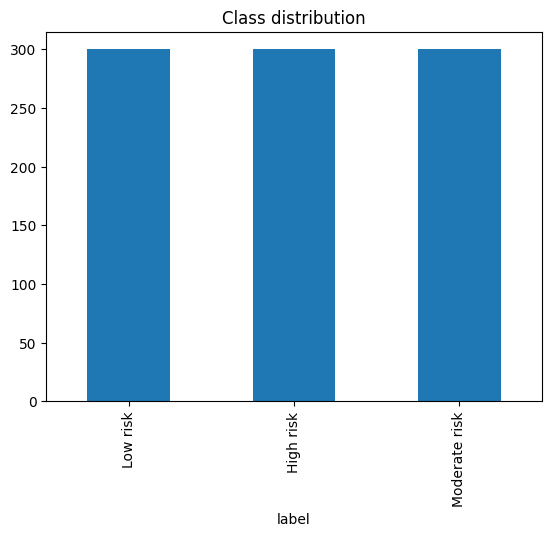

In [6]:
USE_OWN_DATA = False   # set True to upload your own CSV (columns: text, label; 0/1/2)

def make_synthetic(n_per_class=300):
    openers = ["honestly", "lately", "i don't know why but", "today", "this week", "ugh,", "just saying,", ""]
    closers = ["", "", "anyone else?", "just needed to say it.", "that's all.", "idk.", "thanks for reading."]
    low = ["had a great day with my friends", "so excited for the weekend trip", "finished my project and feel proud",
           "enjoying a relaxing walk and some music", "got a good grade today, feeling happy", "cooking dinner with family tonight",
           "feeling motivated and productive", "loving my new hobby", "had a nice chat with an old friend", "life feels pretty good right now"]
    mod = ["feeling anxious all the time and i can't relax", "can't sleep, stressed about everything", "i feel so tired and low lately",
           "overthinking every little thing and it's exhausting", "feel lonely even when i'm around people", "no motivation to do anything anymore",
           "my anxiety is getting worse and i feel overwhelmed", "i cry for no reason and feel empty", "i'm burned out and stressed about work",
           "i feel like nobody understands what i'm going through"]
    high = ["i don't want to live anymore", "everyone would be better off without me", "i feel hopeless and want to end it all",
            "there is no reason to keep going", "i can't take this pain anymore and i want to disappear forever",
            "i've been thinking about killing myself", "i wish i could just go to sleep and never wake up",
            "i am a burden and i want to die", "nothing will ever get better so why bother living", "i have a plan to end my life"]
    rows = []
    for label, bank in [(0, low), (1, mod), (2, high)]:
        for _ in range(n_per_class):
            parts = [random.choice(openers), random.choice(bank), random.choice(closers)]
            if random.random() < 0.3:
                parts.insert(2, random.choice(bank))
            rows.append((" ".join(p for p in parts if p).strip(), label))
    return pd.DataFrame(rows, columns=["text", "label"]).sample(frac=1, random_state=SEED).reset_index(drop=True)

if USE_OWN_DATA:
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(next(iter(up)))
    assert {"text", "label"} <= set(df.columns), "CSV needs 'text' and 'label' columns"
else:
    df = make_synthetic()

print(df.shape)
display(df.sample(5, random_state=1))
df["label"].map(LABELS).value_counts().plot(kind="bar", title="Class distribution"); plt.show()

In [8]:
CONTRACTIONS = {"can't": "cannot", "won't": "will not", "don't": "do not", "i'm": "i am", "i've": "i have",
                "i'd": "i would", "isn't": "is not", "wasn't": "was not", "n't": " not"}

def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"@\w+", " ", t)
    t = re.sub(r"#", " ", t)
    for k, v in CONTRACTIONS.items():
        t = t.replace(k, v)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["text"].apply(clean_text)
df = df[df["clean"].str.len() > 0].reset_index(drop=True)
display(df[["text", "clean", "label"]].head())


,text,clean,label
0,honestly so excited for the weekend trip just ...,honestly so excited for the weekend trip just ...,0
1,"just saying, i can't take this pain anymore an...",just saying i cannot take this pain anymore an...,2
2,"just saying, feeling motivated and productive ...",just saying feeling motivated and productive h...,0
3,"just saying, feeling anxious all the time and ...",just saying feeling anxious all the time and i...,1
4,today loving my new hobby had a great day with...,today loving my new hobby had a great day with...,0


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, stratify=df["label"], random_state=SEED)

tfidf = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=30000, sublinear_tf=True)

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "LinearSVM (calibrated)": CalibratedClassifierCV(LinearSVC(class_weight="balanced"), cv=3),
}

results, fitted = {}, {}
for name, clf in models.items():
    pipe = Pipeline([("tfidf", tfidf()), ("clf", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results[name] = {"accuracy": accuracy_score(y_test, pred), "macro_f1": f1_score(y_test, pred, average="macro")}
    fitted[name] = pipe

display(pd.DataFrame(results).T.round(3))

,accuracy,macro_f1
LogisticRegression,1.0,1.0
LinearSVM (calibrated),1.0,1.0


Best model: LogisticRegression 

               precision    recall  f1-score   support

     Low risk       1.00      1.00      1.00        60
Moderate risk       1.00      1.00      1.00        60
    High risk       1.00      1.00      1.00        60

     accuracy                           1.00       180
    macro avg       1.00      1.00      1.00       180
 weighted avg       1.00      1.00      1.00       180



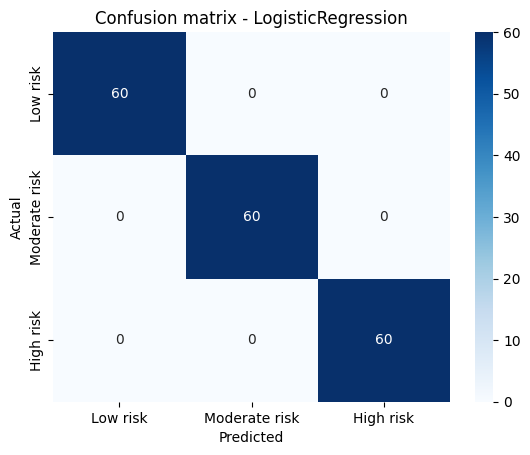

In [12]:
best_name = max(results, key=lambda k: results[k]["macro_f1"])
best = fitted[best_name]
pred = best.predict(X_test)
print("Best model:", best_name, "\n")
print(classification_report(y_test, pred, target_names=list(LABELS.values())))

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS.values(), yticklabels=LABELS.values())
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix - {best_name}"); plt.show()

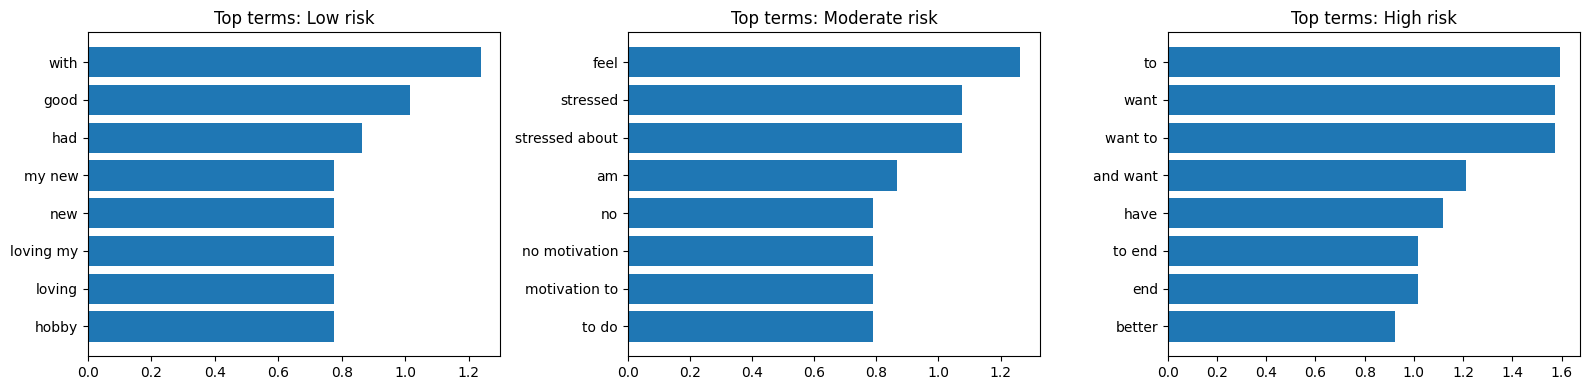

In [14]:
lr = fitted["LogisticRegression"]
vec, clf = lr.named_steps["tfidf"], lr.named_steps["clf"]
feats = np.array(vec.get_feature_names_out())
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, ax in enumerate(axes):
    idx = np.argsort(clf.coef_[i])[-8:]
    ax.barh(feats[idx], clf.coef_[i][idx]); ax.set_title(f"Top terms: {LABELS[i]}")
plt.tight_layout(); plt.show()

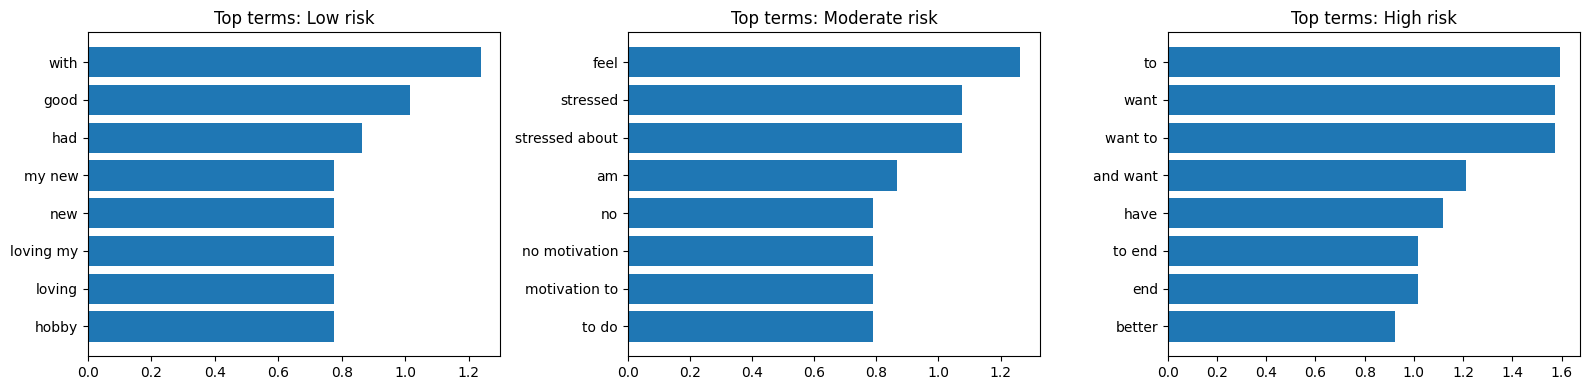

In [16]:
lr = fitted["LogisticRegression"]
vec, clf = lr.named_steps["tfidf"], lr.named_steps["clf"]
feats = np.array(vec.get_feature_names_out())
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, ax in enumerate(axes):
    idx = np.argsort(clf.coef_[i])[-8:]
    ax.barh(feats[idx], clf.coef_[i][idx]); ax.set_title(f"Top terms: {LABELS[i]}")
plt.tight_layout(); plt.show()

In [18]:
HIGH_RISK_PATTERNS = [
    r"kill(ing)? myself", r"end (it all|my life)", r"want to die", r"don.?t want to (live|be here)",
    r"suicid", r"better off without me", r"never wake up", r"plan to end", r"take my own life",
]

def rule_flag(text):
    t = text.lower()
    return any(re.search(p, t) for p in HIGH_RISK_PATTERNS)

def predict_risk(text, model=None):
    model = model or best
    cleaned = clean_text(text)
    proba = model.predict_proba([cleaned])[0]
    classes = list(model.classes_)
    p = {c: proba[classes.index(c)] if c in classes else 0.0 for c in LABELS}
    score = round(100 * (p[2] + 0.5 * p[1]), 1)
    flagged = rule_flag(text)
    if flagged:
        score = max(score, 90.0)
    level = "High risk" if (score >= 66 or flagged) else "Moderate risk" if score >= 33 else "Low risk"
    advice = {
        "Low risk": "No strong risk indicators detected.",
        "Moderate risk": "Signs of stress/low mood. Suggest self-care, talking to someone trusted, or a counsellor.",
        "High risk": "Potential crisis language. Encourage immediate support: Tele-MANAS 14416 / local emergency services.",
    }[level]
    return {"score": score, "level": level, "rule_flag": flagged,
            "probabilities": {LABELS[c]: round(float(p[c]), 3) for c in LABELS}, "advice": advice}

for s in ["Had an amazing day at the park with my friends!",
          "I'm so stressed and can't sleep, everything feels overwhelming",
          "I don't want to live anymore, everyone would be better off without me"]:
    print(s, "\n ->", predict_risk(s), "\n")

Had an amazing day at the park with my friends! 
 -> {'score': np.float64(7.0), 'level': 'Low risk', 'rule_flag': False, 'probabilities': {'Low risk': 0.903, 'Moderate risk': 0.054, 'High risk': 0.043}, 'advice': 'No strong risk indicators detected.'} 

I'm so stressed and can't sleep, everything feels overwhelming 
 -> {'score': np.float64(49.4), 'level': 'Moderate risk', 'rule_flag': False, 'probabilities': {'Low risk': 0.087, 'Moderate risk': 0.839, 'High risk': 0.074}, 'advice': 'Signs of stress/low mood. Suggest self-care, talking to someone trusted, or a counsellor.'} 

I don't want to live anymore, everyone would be better off without me 
 -> {'score': np.float64(98.5), 'level': 'High risk', 'rule_flag': True, 'probabilities': {'Low risk': 0.01, 'Moderate risk': 0.011, 'High risk': 0.979}, 'advice': 'Potential crisis language. Encourage immediate support: Tele-MANAS 14416 / local emergency services.'} 



,post,score,level,rolling_avg
0,Excited for the weekend!,8.0,Low risk,8.0
1,Work is stressing me out lately,56.1,Moderate risk,32.0
2,"I can't sleep, feeling so low",46.8,Moderate risk,37.0
3,I feel empty and nobody understands me,50.5,Moderate risk,51.1
4,"I feel hopeless, no reason to keep going",88.1,High risk,61.8


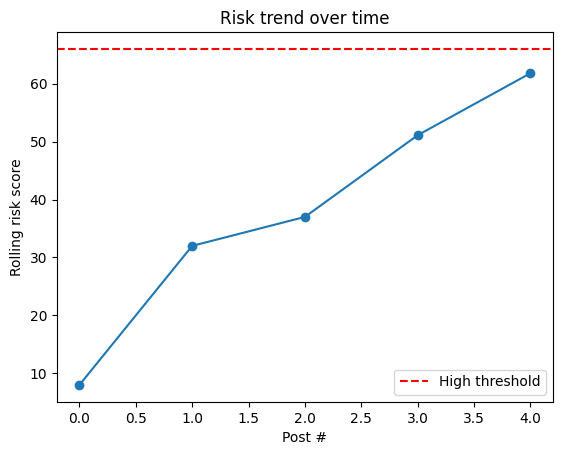

In [20]:
def analyse_timeline(posts):
    rows = [{"post": p[:70], **{k: v for k, v in predict_risk(p).items() if k in ("score", "level")}} for p in posts]
    out = pd.DataFrame(rows)
    out["rolling_avg"] = out["score"].rolling(3, min_periods=1).mean().round(1)
    return out

demo_posts = ["Excited for the weekend!", "Work is stressing me out lately", "I can't sleep, feeling so low",
              "I feel empty and nobody understands me", "I feel hopeless, no reason to keep going"]
tl = analyse_timeline(demo_posts)
display(tl)
plt.plot(tl["rolling_avg"], marker="o"); plt.axhline(66, color="r", ls="--", label="High threshold")
plt.title("Risk trend over time"); plt.xlabel("Post #"); plt.ylabel("Rolling risk score"); plt.legend(); plt.show()

In [22]:
import gradio as gr

def ui_predict(text):
    if not text.strip():
        return {}, "Please enter some text.", ""
    r = predict_risk(text)
    summary = f"Risk score: {r['score']}/100  |  Level: {r['level']}" + ("  |  Safety rule triggered" if r["rule_flag"] else "")
    return r["probabilities"], summary, r["advice"]

demo = gr.Interface(
    fn=ui_predict,
    inputs=gr.Textbox(lines=4, label="Paste a social media post"),
    outputs=[gr.Label(label="Class probabilities"), gr.Textbox(label="Result"), gr.Textbox(label="Suggested next step")],
    title="Mental Health Risk Predictor (Prototype)",
    description="Research prototype - not a medical diagnosis. In crisis? India: Tele-MANAS 14416.",
    examples=[["Had a great day with friends!"], ["I'm exhausted and anxious all the time"], ["I don't want to live anymore"]],
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://491ae78cf855f29100.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [24]:
joblib.dump(best, "mh_risk_model.joblib")
loaded = joblib.load("mh_risk_model.joblib")
print(predict_risk("I feel so low and tired lately", model=loaded))

{'score': np.float64(48.6), 'level': 'Moderate risk', 'rule_flag': False, 'probabilities': {'Low risk': 0.104, 'Moderate risk': 0.819, 'High risk': 0.077}, 'advice': 'Signs of stress/low mood. Suggest self-care, talking to someone trusted, or a counsellor.'}


In [ ]:
!pip -q install transformers datasets accelerate
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer

ckpt = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(ckpt)
tr = Dataset.from_pandas(pd.DataFrame({"text": X_train.values, "label": y_train.values}))
te = Dataset.from_pandas(pd.DataFrame({"text": X_test.values, "label": y_test.values}))
enc = lambda b: tok(b["text"], truncation=True, padding="max_length", max_length=128)
tr, te = tr.map(enc, batched=True), te.map(enc, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(ckpt, num_labels=3)
args = TrainingArguments(output_dir="bert_out", num_train_epochs=3, per_device_train_batch_size=16,
                         learning_rate=2e-5, eval_strategy="epoch", save_strategy="no", report_to="none")

def metrics(p):
    preds = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, preds), "macro_f1": f1_score(p.label_ids, preds, average="macro")}

trainer = Trainer(model=model, args=args, train_dataset=tr, eval_dataset=te, compute_metrics=metrics)
trainer.train(); print(trainer.evaluate())

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/720 [00:00<?, ? examples/s]

Map:   0%|          | 0/180 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
